In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [3]:
student = pd.read_csv("studentz.csv")

In [4]:
student

,hours_studied,attendance_pct,previous_score,passed
0,3.7,43.0,33.0,0
1,9.5,72.0,41.0,1
2,7.3,72.0,33.0,1
3,6.0,78.0,27.0,0
4,1.6,84.0,29.0,0
...,...,...,...,...
295,5.2,68.0,35.0,0
296,7.7,80.0,42.0,1
297,2.2,50.0,87.0,0
298,6.2,52.0,21.0,0


In [5]:
X = student.drop(columns="passed")
Y = student["passed"]

X_train, X_test, Y_train, Y_test = train_test_split(
        X, Y, test_size=0.2, random_state=42, stratify=Y
)

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (240, 3) Test: (60, 3)


In [6]:
log_model = make_pipeline(StandardScaler(), LogisticRegression())
log_model.fit(X_train, Y_train)

log_pred = log_model.predict(X_test)
print("Logistic Regression accuracy:", round(accuracy_score(Y_test, log_pred), 3))

Logistic Regression accuracy: 0.917


In [7]:
#predict for a new student
new_student = pd.DataFrame({"hours_studied": [6], "attendance_pct": [85], "previous_score": [60]})

print("predicted class:", log_model.predict(new_student)[0], "(1 = pass, 0 = fail)")
proba = log_model.predict_proba(new_student)[0]
print(f"Probability of failing: {proba[0]:.2f}")
print(f"Probability of passing: {proba[1]:.2f}")

predicted class: 1 (1 = pass, 0 = fail)
Probability of failing: 0.07
Probability of passing: 0.93


In [8]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, Y_train)

tree_pred = tree_model.predict(X_test)
print("Decision Tree Accuracy:", round(accuracy_score(Y_test, tree_pred), 3))

Decision Tree Accuracy: 0.717


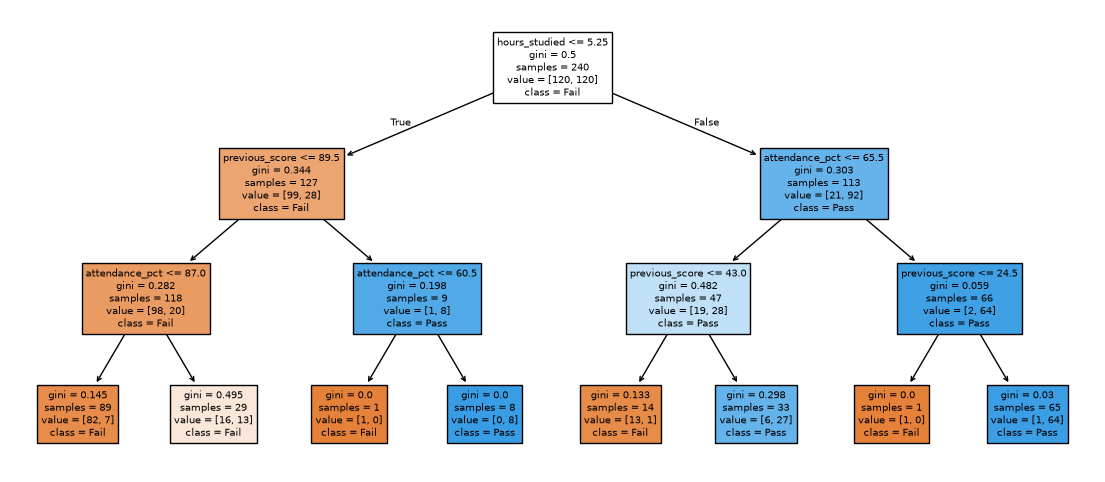

In [9]:
plt.figure(figsize=(14,6))
plot_tree(tree_model, feature_names=X.columns, class_names=["Fail", "Pass"], filled=True, rounded=False)
plt.show()